<a href="https://colab.research.google.com/github/Chaile-Mendez/tp-analisis-labo/blob/Emanuel/TP_GRUPAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib as plt

In [2]:
url = "https://raw.githubusercontent.com/Chaile-Mendez/tp-analisis-labo/Facu/data/raw/dataset_final"
df = pd.read_csv(url)

In [3]:
df.head()

,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status
0,788,22,Male,Graduate,Canada,4.6,Instagram,No,6.7,7.0,NaN
1,703,24,Male,Undergraduate,USA,4.7,YouTube,No,7.0,6.2,NaN
2,610,24,Male,Graduate,India,2.7,Instagram,No,8.6,7.8,NaN
3,699,22,Female,Graduate,USA,6.5,YouTube,Yes,5.4,5.0,NaN
4,302,21,Male,High School,Australia,6.8,YouTube,Yes,5.7,5.0,NaN


In [4]:
print("Nulos por columna:")
print(df.isnull().sum())                                 # isnull() marca cada celda vacía; sum() las cuenta por columna
print("\nFilas duplicadas:", df.duplicated().sum())

Nulos por columna:
Student_ID                         0
Age                                0
Gender                             0
Academic_Level                     0
Country                            0
Avg_Daily_Usage_Hours              0
Most_Used_Platform                 0
Affects_Academic_Performance       0
Sleep_Hours_Per_Night              0
Mental_Health_Score                0
Relationship_Status             1038
dtype: int64

Filas duplicadas: 0


In [5]:
paises_unicos = df['Country'].unique()
print(f"Número de países únicos: {len(paises_unicos)}")
print(paises_unicos)

Número de países únicos: 110
['Canada' 'USA' 'India' 'Australia' 'UK' 'Germany' 'Bangladesh' 'Brazil'
 'Japan' 'South Korea' 'France' 'Spain' 'Italy' 'Mexico' 'Russia' 'China'
 'Sweden' 'Norway' 'Denmark' 'Netherlands' 'Belgium' 'Switzerland'
 'Austria' 'Portugal' 'Greece' 'Ireland' 'New Zealand' 'Singapore'
 'Malaysia' 'Thailand' 'Vietnam' 'Philippines' 'Indonesia' 'Taiwan'
 'Hong Kong' 'Turkey' 'Israel' 'UAE' 'Egypt' 'Morocco' 'South Africa'
 'Nigeria' 'Kenya' 'Ghana' 'Argentina' 'Chile' 'Colombia' 'Peru'
 'Venezuela' 'Ecuador' 'Uruguay' 'Paraguay' 'Bolivia' 'Costa Rica'
 'Panama' 'Jamaica' 'Trinidad' 'Bahamas' 'Iceland' 'Finland' 'Poland'
 'Romania' 'Hungary' 'Czech Republic' 'Slovakia' 'Croatia' 'Serbia'
 'Slovenia' 'Bulgaria' 'Estonia' 'Latvia' 'Lithuania' 'Ukraine' 'Moldova'
 'Belarus' 'Kazakhstan' 'Uzbekistan' 'Kyrgyzstan' 'Tajikistan' 'Armenia'
 'Georgia' 'Azerbaijan' 'Cyprus' 'Malta' 'Luxembourg' 'Monaco' 'Andorra'
 'San Marino' 'Vatican City' 'Liechtenstein' 'Montenegro' 'Alb

In [6]:
# Diccionario: país -> continente
continentes = {
    # América del Norte
    'Canada': 'América del Norte',
    'USA': 'América del Norte',
    'Mexico': 'América del Norte',
    'Costa Rica': 'América del Norte',
    'Panama': 'América del Norte',
    'Jamaica': 'América del Norte',
    'Trinidad': 'América del Norte',
    'Bahamas': 'América del Norte',

    # América del Sur
    'Brazil': 'América del Sur',
    'Argentina': 'América del Sur',
    'Chile': 'América del Sur',
    'Colombia': 'América del Sur',
    'Peru': 'América del Sur',
    'Venezuela': 'América del Sur',
    'Ecuador': 'América del Sur',
    'Uruguay': 'América del Sur',
    'Paraguay': 'América del Sur',
    'Bolivia': 'América del Sur',

    # Europa
    'UK': 'Europa',
    'Germany': 'Europa',
    'France': 'Europa',
    'Spain': 'Europa',
    'Italy': 'Europa',
    'Sweden': 'Europa',
    'Norway': 'Europa',
    'Denmark': 'Europa',
    'Netherlands': 'Europa',
    'Belgium': 'Europa',
    'Switzerland': 'Europa',
    'Austria': 'Europa',
    'Portugal': 'Europa',
    'Greece': 'Europa',
    'Ireland': 'Europa',
    'Iceland': 'Europa',
    'Finland': 'Europa',
    'Poland': 'Europa',
    'Romania': 'Europa',
    'Hungary': 'Europa',
    'Czech Republic': 'Europa',
    'Slovakia': 'Europa',
    'Croatia': 'Europa',
    'Serbia': 'Europa',
    'Slovenia': 'Europa',
    'Bulgaria': 'Europa',
    'Estonia': 'Europa',
    'Latvia': 'Europa',
    'Lithuania': 'Europa',
    'Ukraine': 'Europa',
    'Moldova': 'Europa',
    'Belarus': 'Europa',
    'Cyprus': 'Europa',
    'Malta': 'Europa',
    'Luxembourg': 'Europa',
    'Monaco': 'Europa',
    'Andorra': 'Europa',
    'San Marino': 'Europa',
    'Vatican City': 'Europa',
    'Liechtenstein': 'Europa',
    'Montenegro': 'Europa',
    'Albania': 'Europa',
    'North Macedonia': 'Europa',
    'Kosovo': 'Europa',
    'Bosnia': 'Europa',

    # Asia
    'India': 'Asia',
    'Bangladesh': 'Asia',
    'Japan': 'Asia',
    'South Korea': 'Asia',
    'China': 'Asia',
    'Singapore': 'Asia',
    'Malaysia': 'Asia',
    'Thailand': 'Asia',
    'Vietnam': 'Asia',
    'Philippines': 'Asia',
    'Indonesia': 'Asia',
    'Taiwan': 'Asia',
    'Hong Kong': 'Asia',
    'Turkey': 'Asia',
    'Israel': 'Asia',
    'UAE': 'Asia',
    'Kazakhstan': 'Asia',
    'Uzbekistan': 'Asia',
    'Kyrgyzstan': 'Asia',
    'Tajikistan': 'Asia',
    'Armenia': 'Asia',
    'Georgia': 'Asia',
    'Azerbaijan': 'Asia',
    'Qatar': 'Asia',
    'Kuwait': 'Asia',
    'Bahrain': 'Asia',
    'Oman': 'Asia',
    'Jordan': 'Asia',
    'Lebanon': 'Asia',
    'Iraq': 'Asia',
    'Yemen': 'Asia',
    'Syria': 'Asia',
    'Afghanistan': 'Asia',
    'Pakistan': 'Asia',
    'Nepal': 'Asia',
    'Bhutan': 'Asia',
    'Sri Lanka': 'Asia',
    'Maldives': 'Asia',

    # África
    'Egypt': 'África',
    'Morocco': 'África',
    'South Africa': 'África',
    'Nigeria': 'África',
    'Kenya': 'África',
    'Ghana': 'África',

    # Oceanía
    'Australia': 'Oceanía',
    'New Zealand': 'Oceanía',

    # Rusia: país transcontinental
    'Russia': 'Europa/Asia',
}

# Crear la nueva columna
df['Continent'] = df['Country'].map(continentes)

# Verificar si hay países sin correspondencia
print(df[df['Continent'].isna()]['Country'].unique())

# Ver una muestra del resultado
print(df[['Country', 'Continent']].head())


[]
     Country          Continent
0     Canada  América del Norte
1        USA  América del Norte
2      India               Asia
3        USA  América del Norte
4  Australia            Oceanía


In [7]:
df.head()

,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status,Continent
0,788,22,Male,Graduate,Canada,4.6,Instagram,No,6.7,7.0,NaN,América del Norte
1,703,24,Male,Undergraduate,USA,4.7,YouTube,No,7.0,6.2,NaN,América del Norte
2,610,24,Male,Graduate,India,2.7,Instagram,No,8.6,7.8,NaN,Asia
3,699,22,Female,Graduate,USA,6.5,YouTube,Yes,5.4,5.0,NaN,América del Norte
4,302,21,Male,High School,Australia,6.8,YouTube,Yes,5.7,5.0,NaN,Oceanía


In [8]:
continentes_unicos = df['Continent'].unique()
print(f"Número de países únicos: {len(continentes_unicos)}")
print(continentes_unicos)

Número de países únicos: 7
['América del Norte' 'Asia' 'Oceanía' 'Europa' 'América del Sur'
 'Europa/Asia' 'África']


In [9]:
plataformas_unicas = df['Most_Used_Platform'].unique()
print(f"Número de plataformas únicas: {len(plataformas_unicas)}")
print(plataformas_unicas)

Número de plataformas únicas: 12
['Instagram' 'YouTube' 'Facebook' 'TikTok' 'LinkedIn' 'Twitter' 'Snapchat'
 'LINE' 'KakaoTalk' 'VKontakte' 'WhatsApp' 'WeChat']


In [10]:
# Definir la lista de plataformas deseadas
plataformas_interes = ['Instagram', 'YouTube', 'Facebook', 'TikTok', 'Twitter']

# Filtrar el DataFrame
df_filtrado = df[df['Most_Used_Platform'].isin(plataformas_interes)]

# Mostrar información del nuevo dataset filtrado
print(f"Cantidad de filas antes del filtro: {len(df)}")
print(f"Cantidad de filas después del filtro: {len(df_filtrado)}")
print("\nPlataformas que quedaron en el dataset:")
print(df_filtrado['Most_Used_Platform'].unique())

# Mostrar las primeras filas
df_filtrado.head()

Cantidad de filas antes del filtro: 1743
Cantidad de filas después del filtro: 1373

Plataformas que quedaron en el dataset:
['Instagram' 'YouTube' 'Facebook' 'TikTok' 'Twitter']


,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status,Continent
0,788,22,Male,Graduate,Canada,4.6,Instagram,No,6.7,7.0,NaN,América del Norte
1,703,24,Male,Undergraduate,USA,4.7,YouTube,No,7.0,6.2,NaN,América del Norte
2,610,24,Male,Graduate,India,2.7,Instagram,No,8.6,7.8,NaN,Asia
3,699,22,Female,Graduate,USA,6.5,YouTube,Yes,5.4,5.0,NaN,América del Norte
4,302,21,Male,High School,Australia,6.8,YouTube,Yes,5.7,5.0,NaN,Oceanía


In [11]:
# Eliminar la columna Relationship_Status del dataset filtrado
df_final = df_filtrado.drop(columns=['Relationship_Status'])

# Verificar las columnas resultantes
print("Columnas en el nuevo dataset:")
print(df_final.columns.tolist())

# Mostrar una vista previa
df_final.head()

Columnas en el nuevo dataset:
['Student_ID', 'Age', 'Gender', 'Academic_Level', 'Country', 'Avg_Daily_Usage_Hours', 'Most_Used_Platform', 'Affects_Academic_Performance', 'Sleep_Hours_Per_Night', 'Mental_Health_Score', 'Continent']


,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Continent
0,788,22,Male,Graduate,Canada,4.6,Instagram,No,6.7,7.0,América del Norte
1,703,24,Male,Undergraduate,USA,4.7,YouTube,No,7.0,6.2,América del Norte
2,610,24,Male,Graduate,India,2.7,Instagram,No,8.6,7.8,Asia
3,699,22,Female,Graduate,USA,6.5,YouTube,Yes,5.4,5.0,América del Norte
4,302,21,Male,High School,Australia,6.8,YouTube,Yes,5.7,5.0,Oceanía


--- Promedio de Horas de Uso Diario por Plataforma ---
Plataforma  Promedio Horas de Uso
    TikTok               5.367714
   Twitter               4.887379
 Instagram               4.874182
   YouTube               4.798667
  Facebook               4.694237




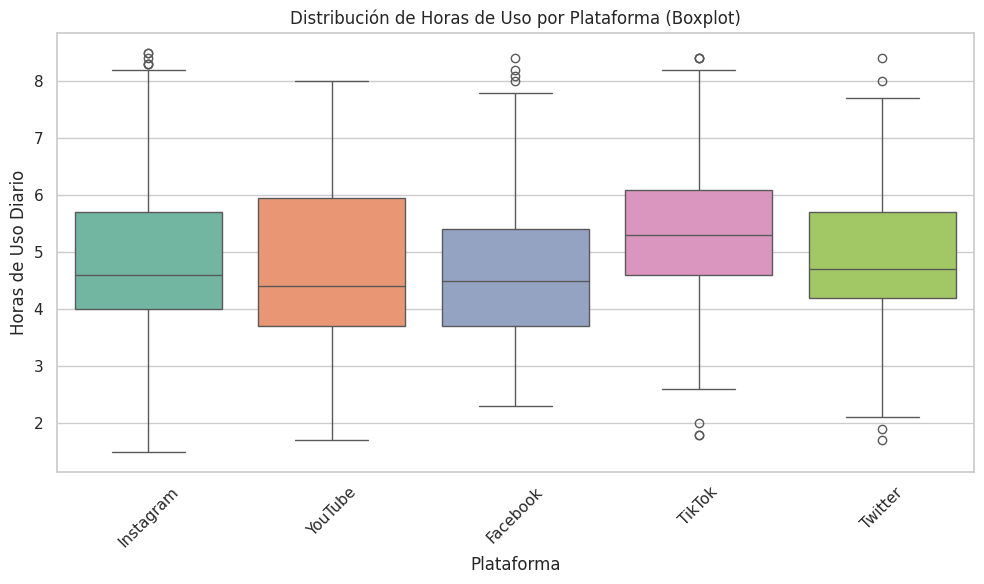

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Tabla del promedio de Avg_Daily_Usage_Hours por Most_Used_Platform
promedio_uso = df_final.groupby('Most_Used_Platform')['Avg_Daily_Usage_Hours'].mean().reset_index()
promedio_uso.columns = ['Plataforma', 'Promedio Horas de Uso']
promedio_uso = promedio_uso.sort_values(by='Promedio Horas de Uso', ascending=False)

print("--- Promedio de Horas de Uso Diario por Plataforma ---")
print(promedio_uso.to_string(index=False))
print("\n")

# Configuración de estilo de gráficos
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# 2. Boxplot: Distribución de horas de uso diario por plataforma (usando df_final)
sns.boxplot(
    data=df_final,
    x='Most_Used_Platform',
    y='Avg_Daily_Usage_Hours',
    hue='Most_Used_Platform',
    palette='Set2',
    legend=False
)
plt.title('Distribución de Horas de Uso por Plataforma (Boxplot)')
plt.xlabel('Plataforma')
plt.ylabel('Horas de Uso Diario')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

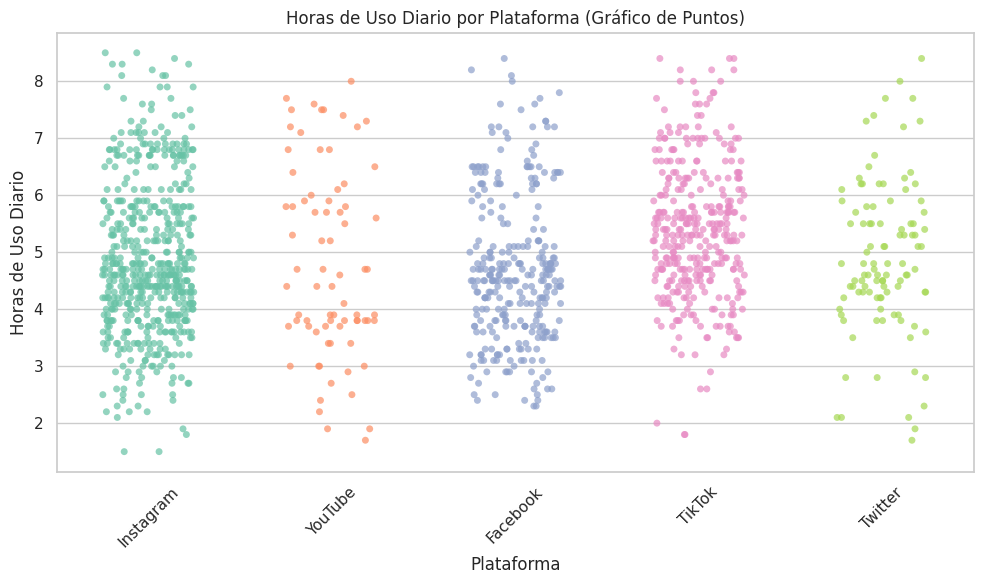

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Gráfico de puntos agrupado por plataforma utilizando df_final
sns.stripplot(
    data=df_final,
    x='Most_Used_Platform',
    y='Avg_Daily_Usage_Hours',
    hue='Most_Used_Platform',
    palette='Set2',
    jitter=0.25,
    size=5,
    alpha=0.7,
    legend=False
)

plt.title('Horas de Uso Diario por Plataforma (Gráfico de Puntos)')
plt.xlabel('Plataforma')
plt.ylabel('Horas de Uso Diario')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Responder

-¿Cuantas horas le dedican a cada red social según edad?
Impacto de las redes en la calidad de vida de los estudiantes en la salud mental

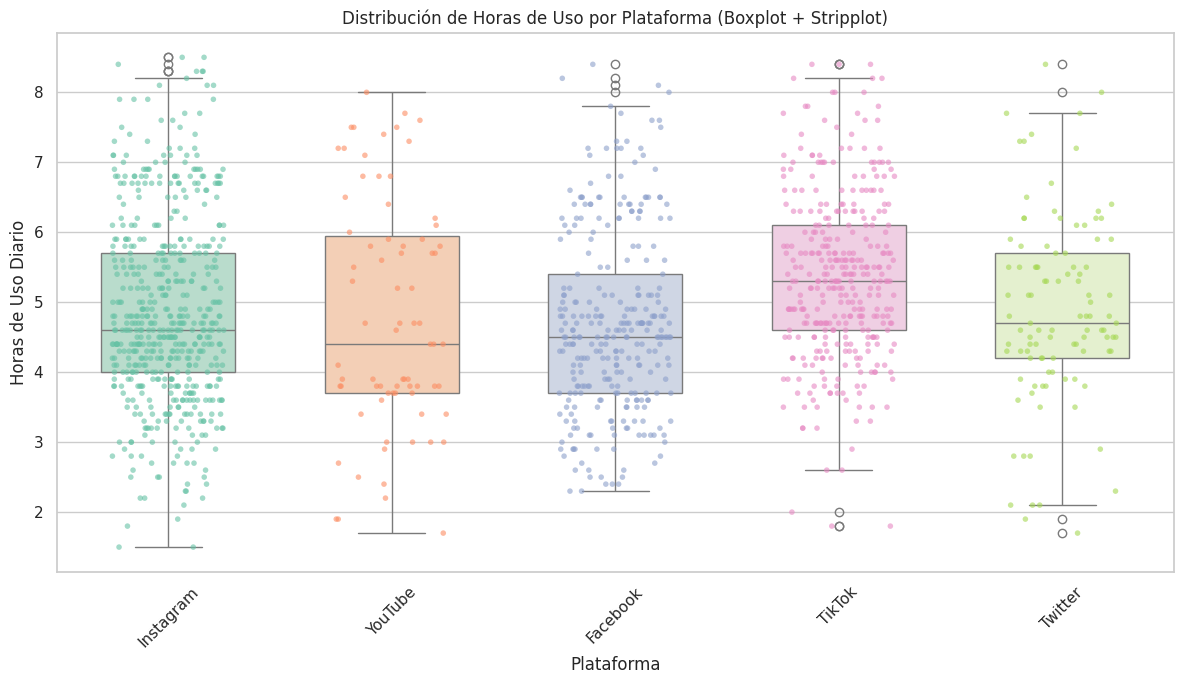

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 7))

# 1. Crear el Boxplot base de fondo
sns.boxplot(
    data=df_final,
    x='Most_Used_Platform',
    y='Avg_Daily_Usage_Hours',
    hue='Most_Used_Platform',
    palette='Pastel2',
    legend=False,
    width=0.6
)

# 2. Superponer el Scatterplot (Stripplot) de los puntos individuales
sns.stripplot(
    data=df_final,
    x='Most_Used_Platform',
    y='Avg_Daily_Usage_Hours',
    hue='Most_Used_Platform',
    palette='Set2',
    jitter=0.25,
    size=4,
    alpha=0.6,
    legend=False
)

plt.title('Distribución de Horas de Uso por Plataforma (Boxplot + Stripplot)')
plt.xlabel('Plataforma')
plt.ylabel('Horas de Uso Diario')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [17]:
# Crear una tabla dinámica (pivot table) para ver el promedio de uso diario por cada edad exacta y plataforma
cuadro_por_edad = df_final.pivot_table(
    values='Avg_Daily_Usage_Hours',
    index='Age',
    columns='Most_Used_Platform',
    aggfunc='mean'
).round(2)

# Llenar posibles valores vacíos (en caso de que no haya registro para una combinación de edad/plataforma) con '-' para mejor lectura
cuadro_por_edad_formateado = cuadro_por_edad.fillna('-')

print("--- Promedio de Horas de Uso Diario por Edad Exacta y Plataforma ---")
display(cuadro_por_edad_formateado)

--- Promedio de Horas de Uso Diario por Edad Exacta y Plataforma ---


Most_Used_Platform,Facebook,Instagram,TikTok,Twitter,YouTube
Age,,,,,
18,4.87,5.69,5.74,4.26,4.22
19,5.40,5.09,5.49,4.78,5.50
20,4.92,4.60,5.43,5.09,4.57
21,4.49,4.72,5.55,4.82,4.57
22,4.39,4.69,4.87,4.88,5.17
23,5.27,5.05,5.02,4.88,4.83
24,5.29,5.91,5.78,5.14,4.98


HORAS QUE LE DEDICAN A CADA RED SOCIAL SEGÚN EDAD

In [18]:
# Adicionalmente, creamos un cuadro con la cantidad de estudiantes (conteo) por edad y plataforma para dar contexto de los datos
cuadro_conteo_edad = df_final.pivot_table(
    values='Avg_Daily_Usage_Hours',
    index='Age',
    columns='Most_Used_Platform',
    aggfunc='count'
).fillna(0).astype(int)

print("--- Cantidad de Alumnos por Edad Exacta y Plataforma ---")
display(cuadro_conteo_edad)

--- Cantidad de Alumnos por Edad Exacta y Plataforma ---


Most_Used_Platform,Facebook,Instagram,TikTok,Twitter,YouTube
Age,,,,,
18,6,15,14,7,8
19,24,182,84,17,8
20,47,134,113,14,13
21,82,134,47,12,20
22,103,47,65,17,14
23,15,28,13,18,6
24,18,10,14,18,6


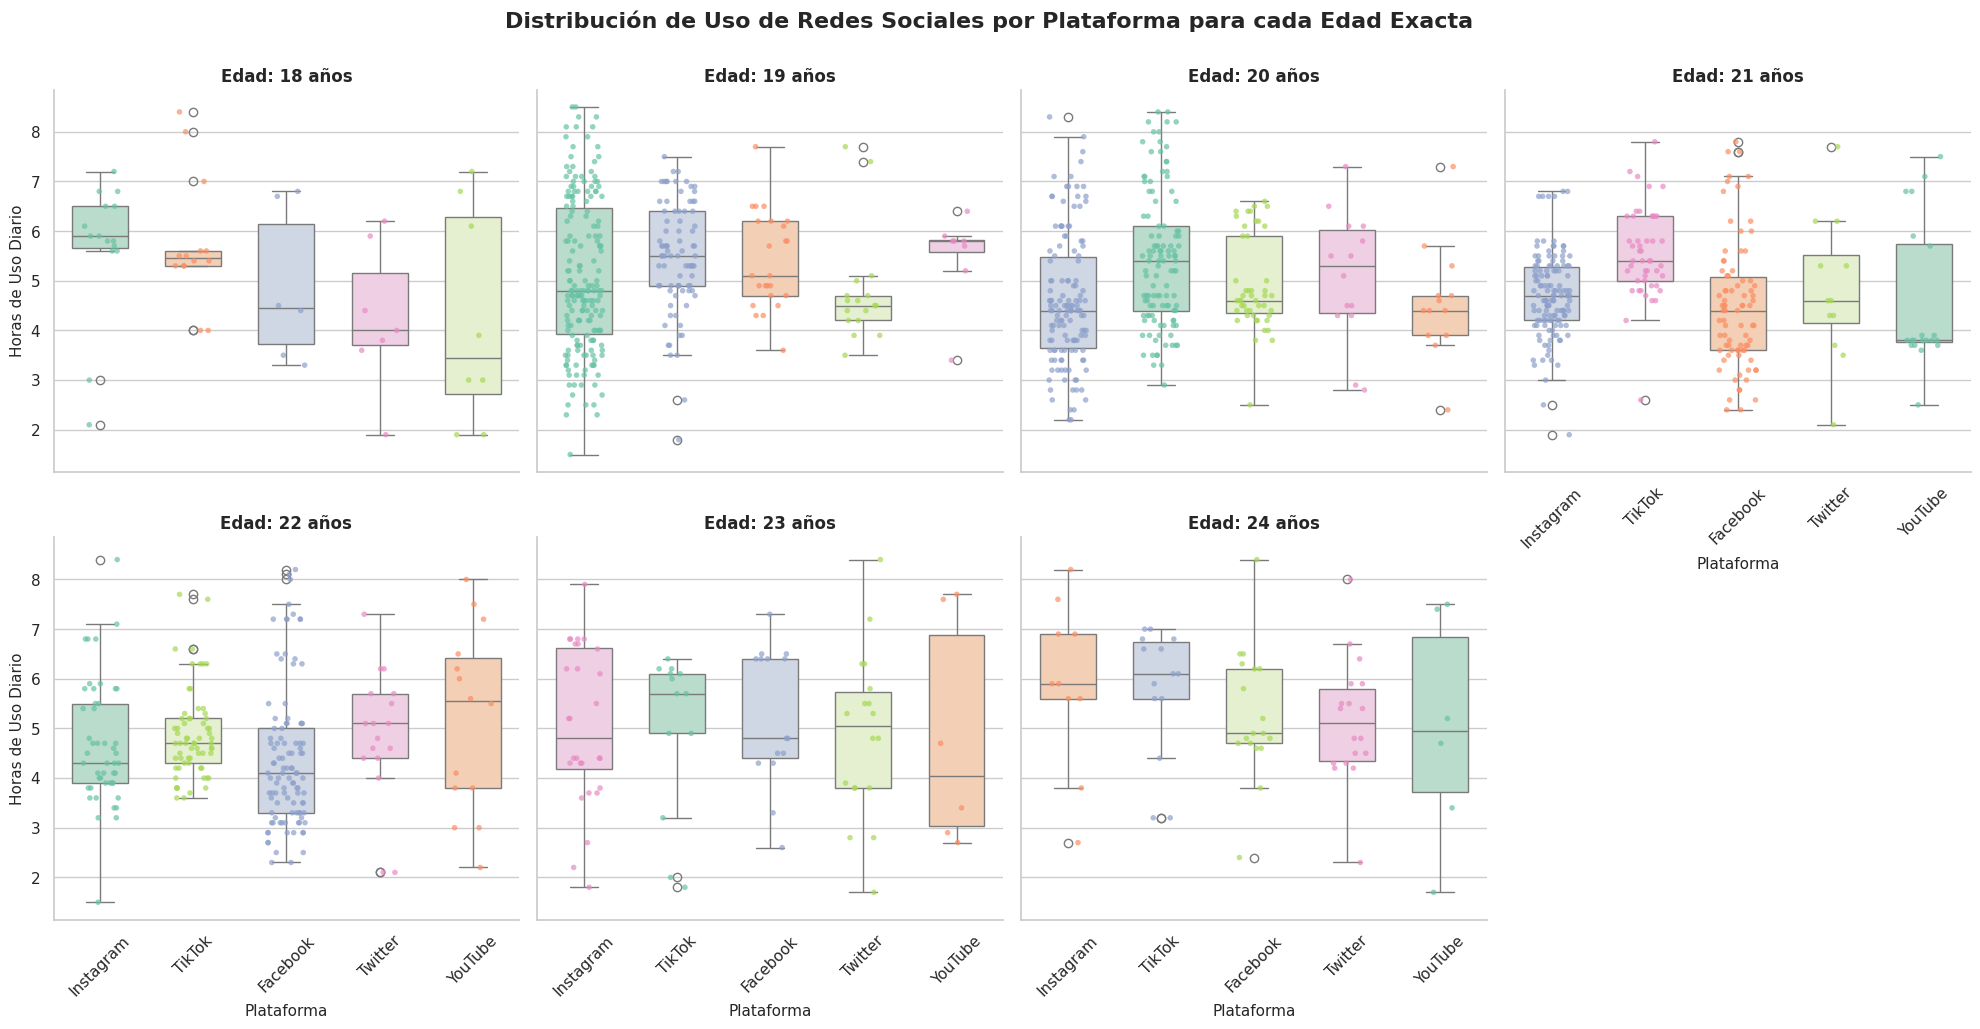

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar el estilo de seaborn
sns.set_theme(style="whitegrid")

# Crear un FacetGrid con un panel para cada edad exacta
g_edades = sns.FacetGrid(
    df_final,
    col="Age",
    col_wrap=4,
    height=5,
    aspect=1.0,
    sharey=True
)

# 1. Dibujar el Boxplot para cada edad en su respectivo panel
g_edades.map_dataframe(
    sns.boxplot,
    x='Most_Used_Platform',
    y='Avg_Daily_Usage_Hours',
    hue='Most_Used_Platform',
    palette='Pastel2',
    legend=False,
    width=0.6
)

# 2. Superponer el Stripplot (scatterplot) con los puntos individuales en cada panel
g_edades.map_dataframe(
    sns.stripplot,
    x='Most_Used_Platform',
    y='Avg_Daily_Usage_Hours',
    hue='Most_Used_Platform',
    palette='Set2',
    jitter=0.2,
    size=4,
    alpha=0.7,
    legend=False
)

# Ajustar los títulos de cada panel, etiquetas y rotación de plataformas
g_edades.set_titles("Edad: {col_name} años", size=12, weight='bold')
g_edades.set_axis_labels("Plataforma", "Horas de Uso Diario", size=11)

for ax in g_edades.axes.flat:
    ax.tick_params(axis='x', labelrotation=45)

plt.subplots_adjust(top=0.9)
g_edades.fig.suptitle('Distribución de Uso de Redes Sociales por Plataforma para cada Edad Exacta', size=16, weight='bold')

plt.show()

In [15]:
# Calcular métricas estadísticas de uso diario agrupado por plataforma
metricas_plataformas = df_final.groupby('Most_Used_Platform')['Avg_Daily_Usage_Hours'].agg(
    Count='count',
    Promedio='mean',
    Mediana='median',
    Minimo='min',
    Maximo='max',
    Desviacion_Estandar='std'
).reset_index()

# Mostrar el DataFrame resultante ordenado por el promedio de uso diario
metricas_plataformas = metricas_plataformas.sort_values(by='Promedio', ascending=False)
display(metricas_plataformas)

,Most_Used_Platform,Count,Promedio,Mediana,Minimo,Maximo,Desviacion_Estandar
2,TikTok,350,5.367714,5.3,1.8,8.4,1.188851
3,Twitter,103,4.887379,4.7,1.7,8.4,1.342786
1,Instagram,550,4.874182,4.6,1.5,8.5,1.337829
4,YouTube,75,4.798667,4.4,1.7,8.0,1.651166
0,Facebook,295,4.694237,4.5,2.3,8.4,1.299896


TikTok es la red social que promedia mayor promedio de tiempo de uso entre todas las redes sociales

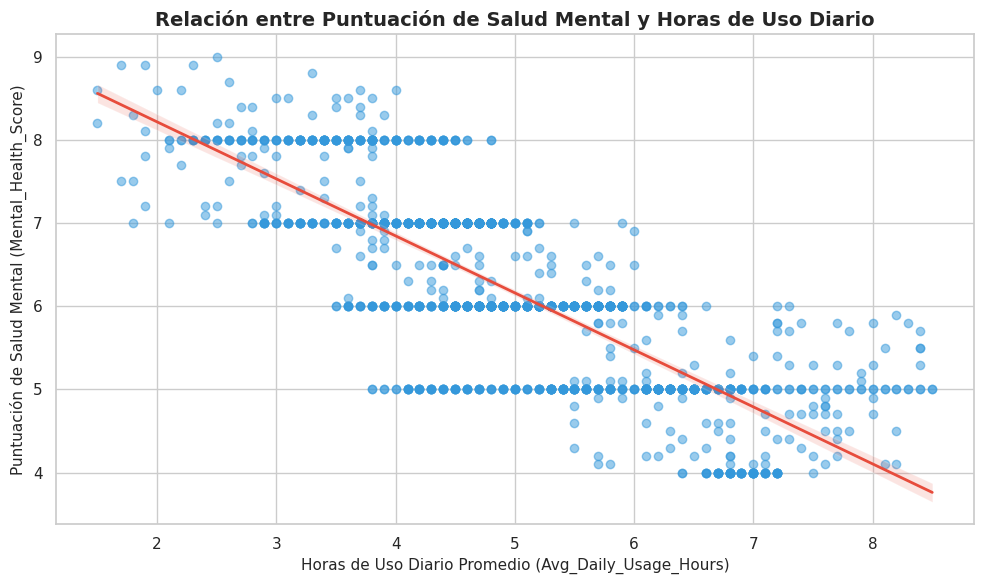

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar el estilo de la visualización
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Crear el gráfico de dispersión con la línea de tendencia intercambiando los ejes
sns.regplot(
    data=df_final,
    x='Avg_Daily_Usage_Hours',
    y='Mental_Health_Score',
    scatter_kws={'alpha':0.5, 'color': '#3498db'},
    line_kws={'color': '#e74c3c', 'linewidth': 2}
)

# Personalizar títulos y etiquetas con el nuevo orden
plt.title('Relación entre Puntuación de Salud Mental y Horas de Uso Diario', size=14, weight='bold')
plt.xlabel('Horas de Uso Diario Promedio (Avg_Daily_Usage_Hours)', size=11)
plt.ylabel('Puntuación de Salud Mental (Mental_Health_Score)', size=11)

# Mostrar el gráfico
plt.tight_layout()
plt.show()

Se puede ver una tendencia clara de como decrece la salud mental de los estudiantes mientras mayor es el uso diario promedio.

E